数据集大小: 290
X形状: torch.Size([10, 1])
y形状: torch.Size([1])

模型参数:
Whh: torch.Size([20, 20])
Whx: torch.Size([20, 1])
bh: torch.Size([20])
Why: torch.Size([1, 20])
by: torch.Size([1])

开始训练...
Epoch [20/100], Train Loss: 0.004781, Test Loss: 0.004876
Epoch [40/100], Train Loss: 0.004901, Test Loss: 0.007292
Epoch [60/100], Train Loss: 0.004286, Test Loss: 0.004136
Epoch [80/100], Train Loss: 0.004266, Test Loss: 0.004486
Epoch [100/100], Train Loss: 0.005654, Test Loss: 0.006295
训练完成！


C:\Users\lenovo\AppData\Roaming\Python\Python39\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lenovo\AppData\Roaming\Python\Python39\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lenovo\AppData\Roaming\Python\Python39\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 21644 (\N{CJK UNIFIED IDEOGRAPH-548C}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lenovo\AppData\Roaming\Python\Python39\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lenovo\AppData\Roaming\Python\Python39\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 357

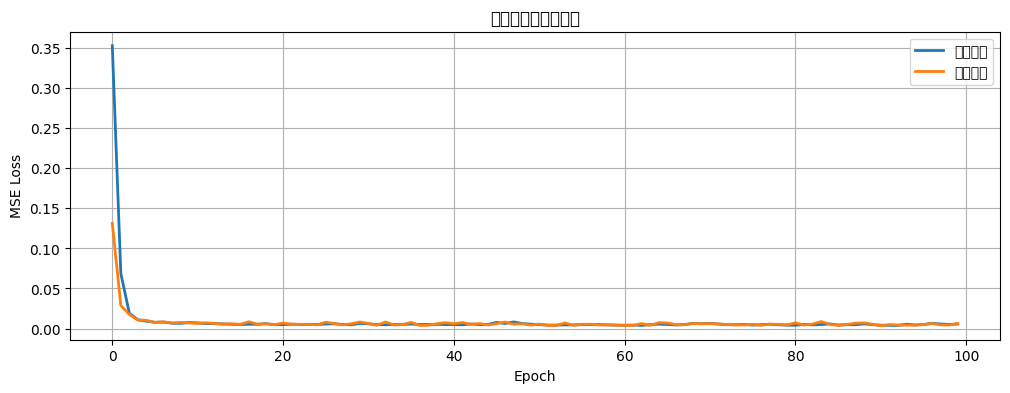


测试集评估指标:
  MSE:  0.006386
  RMSE: 0.079914
  MAE:  0.063850


C:\Users\lenovo\AppData\Local\Temp\ipykernel_44176\43710891.py:197: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from current font.
  plt.tight_layout()
C:\Users\lenovo\AppData\Local\Temp\ipykernel_44176\43710891.py:197: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from current font.
  plt.tight_layout()
C:\Users\lenovo\AppData\Local\Temp\ipykernel_44176\43710891.py:197: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from current font.
  plt.tight_layout()
C:\Users\lenovo\AppData\Local\Temp\ipykernel_44176\43710891.py:197: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from current font.
  plt.tight_layout()
C:\Users\lenovo\AppData\Local\Temp\ipykernel_44176\43710891.py:197: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from current font.
  plt.tight_layout()
C:\Users\lenovo\AppData\Local\Temp\ipykernel_44176\43710891.py:197: UserWarning: Glyph 35797 (\N{CJK UNIFIED IDEOGRAPH-8BD5}) miss

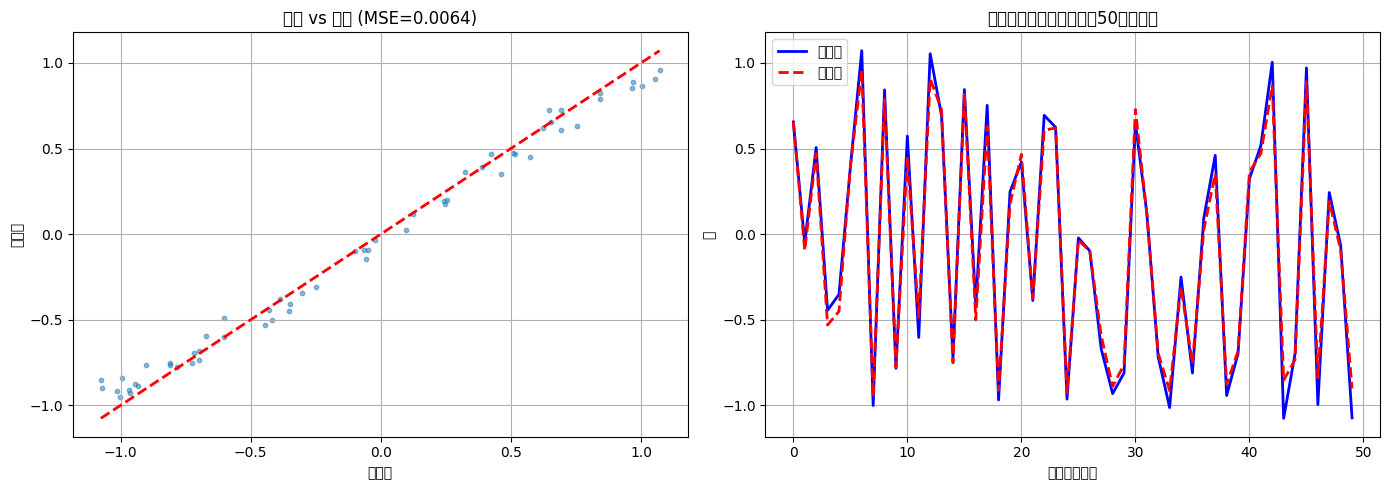

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn

# ============ 1. 生成数据 ============
seq_length = 300
t = np.linspace(0, 50, seq_length)
data = np.sin(t) + np.random.normal(0, 0.05, seq_length)

# ============ 2. 自定义Dataset ============
class TimeSeriesDataset(Dataset):
    def __init__(self, data, window_size):
        self.data = data
        self.window_size = window_size
        
    def __len__(self):
        return len(self.data) - self.window_size
    
    def __getitem__(self, idx):
        X = self.data[idx:idx + self.window_size]
        y = self.data[idx + self.window_size]
        # 增加特征维度: (window_size,) -> (window_size, 1)
        return torch.FloatTensor(X).unsqueeze(-1), torch.FloatTensor([y])

# ============ 3. 创建数据集 ============
window_size = 10
dataset = TimeSeriesDataset(data, window_size)
print(f"数据集大小: {len(dataset)}")

# 查看数据
X, y = dataset[0]
print(f"X形状: {X.shape}")  # torch.Size([10, 1])
print(f"y形状: {y.shape}")  # torch.Size([1])

# ============ 4. 划分数据集 ============
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = torch.utils.data.random_split(
    dataset, [train_size, test_size]
)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=5, shuffle=False)

# ============ 5. 定义RNN模型（input_size=1） ============
class myRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=20, output_size=1):
        super(myRNN, self).__init__()
        
        # 权重矩阵
        self.Whh = nn.Parameter(torch.randn(hidden_size, hidden_size) * 0.01)
        self.Whx = nn.Parameter(torch.randn(hidden_size, input_size) * 0.01)
        self.bh = nn.Parameter(torch.zeros(hidden_size))
        
        self.Why = nn.Parameter(torch.randn(output_size, hidden_size) * 0.01)
        self.by = nn.Parameter(torch.zeros(output_size))
        
        self.hidden_size = hidden_size
        
    def forward(self, x, hidden=None):
        # x形状: (batch, seq_len, input_size)
        batch_size, seq_len, _ = x.shape
        
        if hidden is None:
            hidden = torch.zeros(batch_size, self.hidden_size, device=x.device)
        
        outputs = []
        for t in range(seq_len):
            xt = x[:, t, :]  # (batch, input_size)
            
            # RNN核心公式
            hidden = torch.tanh(
                hidden @ self.Whh.T +  # (batch, hidden_size)
                xt @ self.Whx.T +      # (batch, hidden_size)
                self.bh
            )
            outputs.append(hidden)
        
        outputs = torch.stack(outputs, dim=1)  # (batch, seq_len, hidden_size)
        last_output = outputs[:, -1, :]        # (batch, hidden_size)
        y = last_output @ self.Why.T + self.by # (batch, output_size)
        
        return y, outputs

# ============ 6. 初始化模型 ============
model = myRNN(input_size=1, hidden_size=20, output_size=1)
print("\n模型参数:")
for name, param in model.named_parameters():
    print(f"{name}: {param.shape}")

# ============ 7. 训练 ============
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

epochs = 100
train_losses = []
test_losses = []

print("\n开始训练...")
for epoch in range(epochs):
    # 训练
    model.train()
    train_loss = 0
    for batch_x, batch_y in train_loader:
        # batch_x: (batch, seq_len, 1)
        # batch_y: (batch, 1)
        pred, _ = model(batch_x)
        loss = criterion(pred, batch_y)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
    
    avg_train_loss = train_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    
    # 测试
    model.eval()
    test_loss = 0
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            pred, _ = model(batch_x)
            loss = criterion(pred, batch_y)
            test_loss += loss.item()
    
    avg_test_loss = test_loss / len(test_loader)
    test_losses.append(avg_test_loss)
    
    if (epoch + 1) % 20 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], '
              f'Train Loss: {avg_train_loss:.6f}, '
              f'Test Loss: {avg_test_loss:.6f}')

print("训练完成！")

# ============ 8. 可视化损失 ============
plt.figure(figsize=(12, 4))
plt.plot(train_losses, label='训练损失', linewidth=2)
plt.plot(test_losses, label='测试损失', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('训练和测试损失曲线')
plt.legend()
plt.grid(True)
plt.show()

# ============ 9. 测试集预测 ============
model.eval()
predictions = []
targets = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        pred, _ = model(batch_x)
        predictions.extend(pred.squeeze().numpy())
        targets.extend(batch_y.squeeze().numpy())

predictions = np.array(predictions)
targets = np.array(targets)

# 计算指标
mse = np.mean((predictions - targets) ** 2)
mae = np.mean(np.abs(predictions - targets))
rmse = np.sqrt(mse)

print(f"\n测试集评估指标:")
print(f"  MSE:  {mse:.6f}")
print(f"  RMSE: {rmse:.6f}")
print(f"  MAE:  {mae:.6f}")

# ============ 10. 可视化预测结果 ============
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.scatter(targets, predictions, alpha=0.5, s=10)
plt.plot([targets.min(), targets.max()], 
         [targets.min(), targets.max()], 
         'r--', linewidth=2)
plt.xlabel('真实值')
plt.ylabel('预测值')
plt.title(f'预测 vs 真实 (MSE={mse:.4f})')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(targets[:50], 'b-', label='真实值', linewidth=2)
plt.plot(predictions[:50], 'r--', label='预测值', linewidth=2)
plt.xlabel('测试样本序号')
plt.ylabel('值')
plt.title('测试集预测结果对比（前50个样本）')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()